Motaz Elmashaleh sec 2 1260067 

In [44]:
import os
import pandas as pd 
import matplotlib.pyplot as plt 

ham_files = os.listdir("easy_ham")
spam_files = os.listdir("spam")

load spam and ham email

In [45]:
ham_emails = []

for file_name in ham_files:
    if file_name != "cmds":
        file = open("easy_ham/" + file_name, "r", encoding="latin-1")
        ham_emails.append(file.read())
        file.close()

In [46]:
spam_emails = []

for file_name in spam_files:
    if file_name != "cmds":
        file = open("spam/" + file_name, "r", encoding="latin-1")
        spam_emails.append(file.read())
        file.close()

prepared features and lables 

In [47]:
X = ham_emails + spam_emails

y = [0] * len(ham_emails) + [1] * len(spam_emails)

split dataset train and test 

In [48]:
from sklearn.model_selection import train_test_split


In [49]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

convert the emails to numerical val 

In [50]:
from sklearn.feature_extraction.text import CountVectorizer

In [51]:
vectorizer = CountVectorizer()

X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

train and evalute the classifiers 

In [52]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()
nb_model.fit(X_train_vec, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[1995., 405.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.18,-1.78]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 77547)","[[3051., 291.,2088.,..., 0., 0., 0.], [ 552., 563., 158.,..., 1., 1., 1.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 77547)","[[ -5.9 , -8.24, -6.28,...,-13.92,-13.92,-13.92], [ -6.66, -6.64, -7.91,...,-12.28,-12.28,-12.28]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,77547


In [53]:
y_pred = nb_model.predict(X_test_vec)

In [54]:
from sklearn.metrics import precision_score, recall_score

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

print("Precision:", precision)
print("Recall:", recall)

Precision: 0.9871794871794872
Recall: 0.8105263157894737


In [55]:
from sklearn.linear_model import SGDClassifier

sgd_model = SGDClassifier(random_state=42)
sgd_model.fit(X_train_vec, y_train)

y_pred_sgd = sgd_model.predict(X_test_vec)

In [56]:
print("Precision:", precision_score(y_test, y_pred_sgd))
print("Recall:", recall_score(y_test, y_pred_sgd))

Precision: 0.9894736842105263
Recall: 0.9894736842105263


In [57]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_vec, y_train)

y_pred_lr = lr_model.predict(X_test_vec)

In [58]:
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))

Precision: 0.9693877551020408
Recall: 1.0


In [59]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_lr)
print(cm)

[[503   3]
 [  0  95]]


In [60]:
from sklearn.metrics import f1_score

print("F1 Score:", f1_score(y_test, y_pred_lr))

F1 Score: 0.9844559585492227


table comparsion

In [61]:
import pandas as pd

results = pd.DataFrame({
    "Model": ["Naive Bayes", "SGD", "Logistic Regression"],
    
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, y_pred_sgd),
        precision_score(y_test, y_pred_lr)
    ],
    
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, y_pred_sgd),
        recall_score(y_test, y_pred_lr)
    ],
    
    "F1 Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, y_pred_sgd),
        f1_score(y_test, y_pred_lr)
    ]
})

results

,Model,Precision,Recall,F1 Score
0,Naive Bayes,0.987179,0.810526,0.890173
1,SGD,0.989474,0.989474,0.989474
2,Logistic Regression,0.969388,1.000000,0.984456


visual comp 

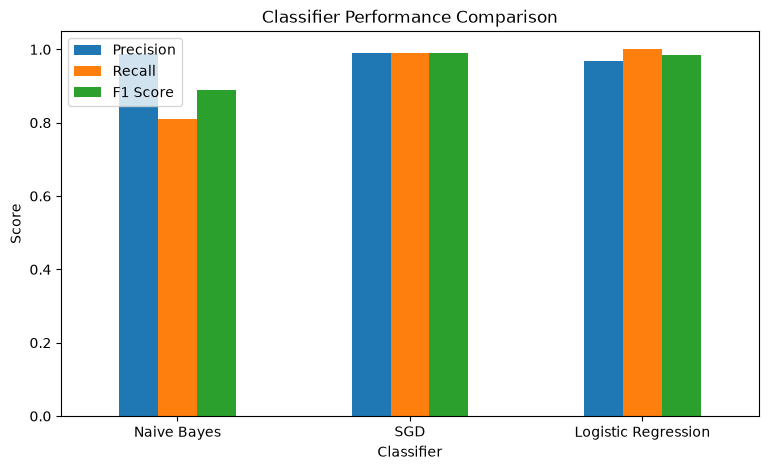

In [63]:
results.set_index("Model")[["Precision", "Recall", "F1 Score"]].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Classifier Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Classifier")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend()
plt.show()